<a href="https://colab.research.google.com/github/avisink/COSC_3327_Patient_Clustering/blob/main/Data_Science_Clustering_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Patient Health Clustering with K-Means
**COSC 3327 – Introduction to Data Science, Final Project**

**Goal:** group patients into health segments using six measurements: age, BMI, cholesterol, resting heart rate, weekly exercise, and sleep. The dataset has no "answer" column, so we are not predicting anything. Instead, K-Means finds patients who look similar to each other and puts them in the same group. Afterwards we look at each group's averages to understand what kind of patient it represents.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 2. Load the dataset
The CSV is stored in our public GitHub repo, so we read it straight from the raw file link. Nothing needs to be uploaded to Colab.

In [2]:
url = "https://raw.githubusercontent.com/avisink/COSC_3327_Patient_Clustering/main/Patient_Health_Clustering.csv"
df = pd.read_csv(url)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (300, 7)


,PatientID,Age,BMI,Cholesterol,RestingHeartRate,WeeklyExerciseHours,SleepHoursPerNight
0,C2000,31.7,33.8,186.2,75.2,2.1,6.0
1,C2001,31.0,21.5,182.2,51.4,7.6,7.4
2,C2002,61.1,31.9,207.0,84.6,0.2,6.1
3,C2003,20.8,23.5,161.1,61.8,7.6,8.0
4,C2004,48.2,33.8,223.6,78.4,3.6,6.8


### What the columns mean
| Column | Meaning |
|---|---|
| `PatientID` | Unique ID for each patient (just a label, not a health measurement) |
| `Age` | Age in years |
| `BMI` | Body Mass Index (weight relative to height; 18.5–24.9 is considered normal, 30+ is obese) |
| `Cholesterol` | Total cholesterol in mg/dL (under 200 is desirable, 240+ is high) |
| `RestingHeartRate` | Heartbeats per minute at rest |
| `WeeklyExerciseHours` | Hours of exercise per week |
| `SleepHoursPerNight` | Average hours of sleep per night |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PatientID            300 non-null    object 
 1   Age                  300 non-null    float64
 2   BMI                  300 non-null    float64
 3   Cholesterol          300 non-null    float64
 4   RestingHeartRate     300 non-null    float64
 5   WeeklyExerciseHours  300 non-null    float64
 6   SleepHoursPerNight   300 non-null    float64
dtypes: float64(6), object(1)
memory usage: 16.5+ KB


In [4]:
df.describe().round(2)

,Age,BMI,Cholesterol,RestingHeartRate,WeeklyExerciseHours,SleepHoursPerNight
count,300.00,300.00,300.00,300.00,300.00,300.00
mean,42.79,28.88,200.08,73.76,3.22,6.54
std,16.14,5.19,29.08,10.45,2.72,1.00
min,18.00,18.60,139.20,48.20,0.00,3.80
25%,29.40,24.58,179.80,66.05,1.30,5.88
50%,38.80,28.90,198.50,73.10,2.30,6.60
75%,56.28,32.70,217.88,81.22,4.53,7.22
max,79.10,44.00,268.90,104.20,12.60,9.00


## 3. Clean and prepare the data
We check for:
1. **Missing values**: K-Means can't handle blanks.
2. **Duplicate patients**: the same patient counted twice would pull the clusters toward them.
3. **Text columns**: K-Means only works with numbers.

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate PatientIDs:", df["PatientID"].duplicated().sum())

Missing values per column:
PatientID              0
Age                    0
BMI                    0
Cholesterol            0
RestingHeartRate       0
WeeklyExerciseHours    0
SleepHoursPerNight     0
dtype: int64

Duplicate rows: 0
Duplicate PatientIDs: 0


There are no missing values and no duplicates, so we don't need to fill or remove anything.

The only text column is `PatientID`. It is just a name tag, not a health measurement, so we **drop** it instead of encoding it. Turning it into a number would make K-Means treat it as meaningful, which would be wrong.

In [6]:
features = df.drop(columns="PatientID")
features.columns.tolist()

['Age',
 'BMI',
 'Cholesterol',
 'RestingHeartRate',
 'WeeklyExerciseHours',
 'SleepHoursPerNight']

### Scaling
K-Means groups points by **distance**, so features with large numbers dominate. Cholesterol values are around 140–270, while sleep is around 4–9 hours. Without scaling, a 10-point cholesterol difference would count far more than a 3-hour sleep difference, even though the sleep difference is much bigger in real terms.

`StandardScaler` rescales every feature to mean 0 and standard deviation 1, so all six features get equal say.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

pd.DataFrame(X_scaled, columns=features.columns).describe().round(2)

,Age,BMI,Cholesterol,RestingHeartRate,WeeklyExerciseHours,SleepHoursPerNight
count,300.00,300.00,300.00,300.00,300.00,300.00
mean,0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.54,-1.98,-2.10,-2.45,-1.19,-2.75
25%,-0.83,-0.83,-0.70,-0.74,-0.71,-0.66
50%,-0.25,0.00,-0.05,-0.06,-0.34,0.06
75%,0.84,0.74,0.61,0.72,0.48,0.69
max,2.25,2.92,2.37,2.92,3.46,2.47


After scaling, every column has a mean of about 0 and a standard deviation of about 1.

## 4. Choose the number of clusters: the elbow method
K-Means needs us to pick **k**, the number of clusters, ahead of time. The elbow method tries k = 1 to 10 and records the **inertia** for each one. Inertia is the total squared distance from each patient to the center of their cluster; lower means tighter groups.

Inertia always drops as k grows (with k = 300, every patient is their own cluster and inertia is 0). So we don't look for the lowest point. We look for the **elbow**: the k after which adding more clusters stops helping much.

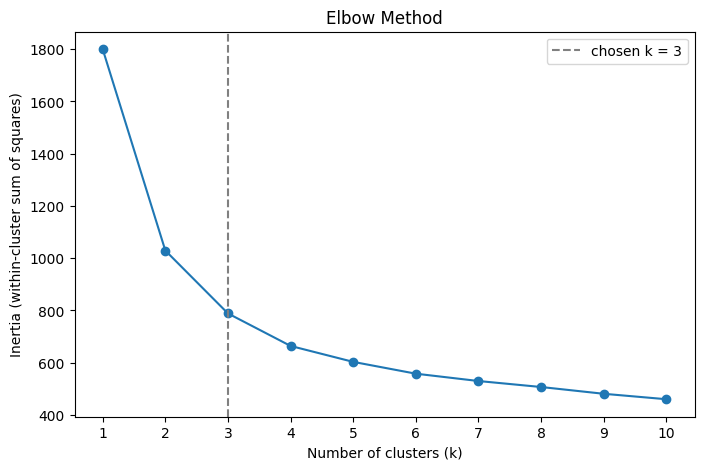

,k,inertia,drop from previous k
0,1,1800.0,NaN
1,2,1029.2,770.8
2,3,788.5,240.8
3,4,664.0,124.4
4,5,603.0,61.0
5,6,557.8,45.2
6,7,529.7,28.1
7,8,506.8,22.9
8,9,480.9,25.9
9,10,460.1,20.8


In [8]:
k_values = range(1, 11)
inertias = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.axvline(3, color="gray", linestyle="--", label="chosen k = 3")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.xticks(k_values)
plt.legend()
plt.show()

pd.DataFrame({"k": list(k_values),
              "inertia": np.round(inertias, 1),
              "drop from previous k": np.round(-np.diff([np.nan] + inertias), 1)})

**Reading the elbow plot:** inertia falls steeply from k = 1 to k = 2 and again from 2 to 3. After k = 3 the curve flattens: each extra cluster removes much less inertia than the one before. So the bend, the "elbow", is at **k = 3**. More clusters would split patients into groups that are only slightly different from each other, which makes them harder to interpret without adding much.

## 5. Train the K-Means model (k = 3)
`n_init=10` runs K-Means 10 times from different random starting points and keeps the best result. `random_state=42` makes the results the same every time the notebook runs.

In [9]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_scaled)

# K-Means numbers its clusters arbitrarily, so renumber them from youngest to
# oldest average age. That way cluster 0/1/2 means the same thing on every run.
order = pd.Series(labels).groupby(labels).apply(lambda idx: df.loc[idx.index, "Age"].mean()).sort_values().index
relabel = {old: new for new, old in enumerate(order)}
df["Cluster"] = pd.Series(labels).map(relabel)

df["Cluster"].value_counts().sort_index().rename("patients")

,patients
Cluster,
0,75
1,147
2,78


## 6. Visualize the clusters
We have six features, but a plot only has two axes. **PCA** (Principal Component Analysis) compresses the six scaled features into two new axes that keep as much of the spread between patients as possible. We use PCA only to draw the picture; the clustering itself used all six features.

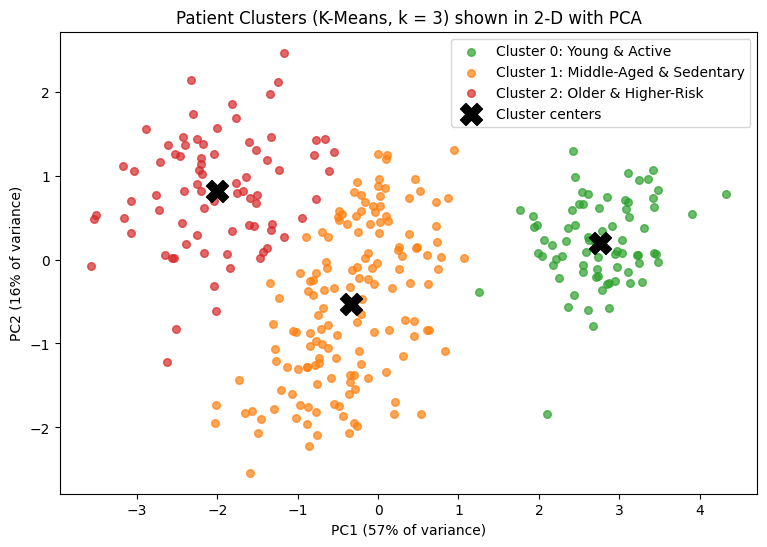

The two PCA axes together keep 72% of the information in the six features.


In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_[order])
explained = pca.explained_variance_ratio_

cluster_names = {0: "Young & Active", 1: "Middle-Aged & Sedentary", 2: "Older & Higher-Risk"}
colors = {0: "tab:green", 1: "tab:orange", 2: "tab:red"}

plt.figure(figsize=(9, 6))
for c in sorted(cluster_names):
    mask = df["Cluster"] == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=30, alpha=0.7,
                color=colors[c], label=f"Cluster {c}: {cluster_names[c]}")
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], s=250, marker="X",
            color="black", label="Cluster centers")
plt.title("Patient Clusters (K-Means, k = 3) shown in 2-D with PCA")
plt.xlabel(f"PC1 ({explained[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({explained[1]:.0%} of variance)")
plt.legend()
plt.show()

print(f"The two PCA axes together keep {explained.sum():.0%} of the information in the six features.")

**Reading the cluster plot:** Cluster 0 (green) sits on its own on the right, well separated from everyone else. That group is very different from the other patients. Clusters 1 and 2 (orange and red) are next to each other and touch at their edge. Those patients are more alike, and the boundary between them is less sharp, which is expected for real health data. Cluster 1 sits between the other two, which matches its in-between averages in the next section.

## 7. What does each cluster represent?
To understand the clusters, we compare their average values in the **original units** (years, mg/dL, hours), not the scaled values.

In [11]:
profile = df.groupby("Cluster")[features.columns].mean().round(1)
profile.insert(0, "Patients", df["Cluster"].value_counts().sort_index())
profile.index = [f"{c}: {cluster_names[c]}" for c in profile.index]
profile

,Patients,Age,BMI,Cholesterol,RestingHeartRate,WeeklyExerciseHours,SleepHoursPerNight
0: Young & Active,75,27.8,22.4,169.7,62.2,7.3,7.4
1: Middle-Aged & Sedentary,147,38.6,30.9,197.9,75.5,2.2,6.3
2: Older & Higher-Risk,78,65.1,31.2,233.5,81.6,1.3,6.1


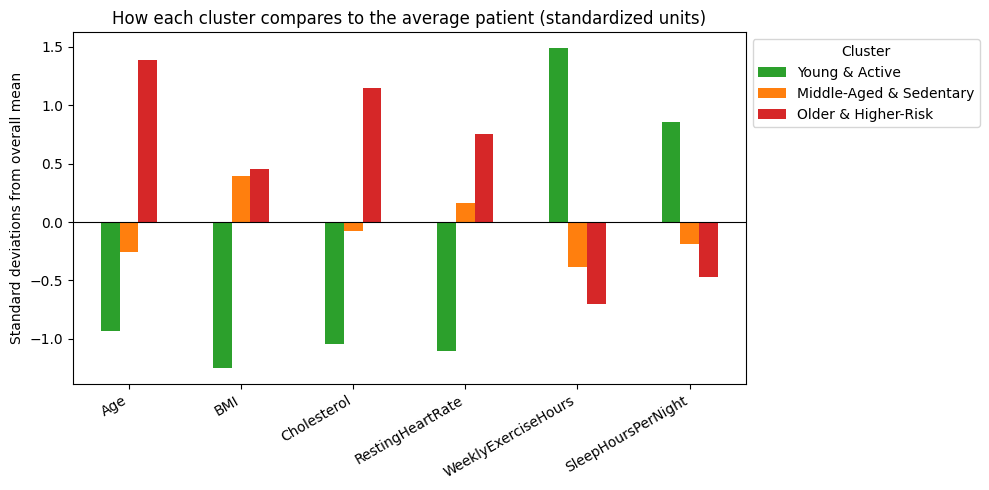

In [12]:
# Side-by-side comparison: each feature's cluster averages, scaled so the
# overall average patient = 0. Bars above 0 are higher than average, below 0 lower.
centers_scaled = pd.DataFrame(kmeans.cluster_centers_[order], columns=features.columns,
                              index=[cluster_names[c] for c in range(3)])
centers_scaled.T.plot(kind="bar", figsize=(10, 5), color=[colors[c] for c in range(3)])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("How each cluster compares to the average patient (standardized units)")
plt.ylabel("Standard deviations from overall mean")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Cluster", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 8. Results in plain language
K-Means split the 300 patients into three health segments:

- **Cluster 0: Young & Active** (about 75 patients). Average age is in the late 20s. This group has the healthiest numbers on every measure: normal BMI (~22), the lowest cholesterol (~170), the lowest resting heart rate (~62), the most exercise (~7 hours/week), and the most sleep (~7.4 hours/night).
- **Cluster 1: Middle-Aged & Sedentary** (about 147 patients, the largest group). Average age is around 39. Their BMI is about as high as the oldest group's (~31, the obese range), and they exercise only ~2 hours a week. Cholesterol (~198) and heart rate (~75) are in the middle. Lifestyle, more than age, separates this group from the healthy one.
- **Cluster 2: Older & Higher-Risk** (about 78 patients). Average age is around 65. They have the highest cholesterol (~234, near the 240 "high" line), the highest resting heart rate (~82), high BMI (~31), the least exercise (~1 hour/week) and the least sleep (~6 hours).

**What this means:** the features move together. Patients who exercise more tend to have lower BMI, lower heart rate, lower cholesterol, and better sleep. That's why K-Means found a clear "healthy, active" group and a clear "at-risk" group. The middle cluster is worth noticing: these patients are not old, but their weight and activity levels already look like the older high-risk group's. A clinic could use these segments to target care, for example by offering lifestyle and exercise programs to Cluster 1 before their risk factors get worse.

**Limitations:** K-Means always produces exactly k groups, even when the real boundaries are fuzzy, and the plot shows Clusters 1 and 2 running into each other. The elbow at k = 3 is a judgment call; k = 4 would also be reasonable and would split the middle group further. These are groupings, not diagnoses: the clusters describe patterns in this dataset and aren't medical categories.